# Method A: range-angle map and MVDR beams

Method A is the chain we used to validate SiViS and to compare radar placements: build a range-angle map, pick one cell per simulator with a physical spacing rule, form one MVDR beam per cell over a small range gate, and read the rates from the phase of each beam. The second half follows the multi-person version of the method, which builds the map from the covariance of the 12 virtual channels and adds a subspace step for two people in the same range bin.

The scene is the one from `00_signal_model`: two people at 2.0 m (−25° and +20°) and one at 2.6 m, with a bed, a wall and a static reflection inside the first person's bin.

In [1]:
import sys
sys.path.insert(0, "..")
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
                     "axes.prop_cycle": plt.cycler(color=["#1b4965", "#c8553d", "#5c946e", "#8c6d9f"])})
from radar import assign, beams, cube, simulate, sivis, spatial, vitals

people = [simulate.Person(2.0, -25, rr=14, hr=80),
          simulate.Person(2.0, 20, rr=22, hr=90, amp=0.8),
          simulate.Person(2.6, 5, rr=20, hr=110, amp=0.9)]
clutter = [(1.2, 0, 3.0), (3.5, -40, 2.0), (2.0, -25, 0.6)]
x, truth = simulate.simulate(people, duration=60, clutter=clutter, snr_db=20)
cfg, fs, t = truth["config"], truth["config"].frame_rate, truth["t"]
rp = cube.compensate_aop(cube.range_fft(x))
pos, rax = cube.aop_positions(), cfg.range_axis()
angles = np.arange(-70, 70.5, 0.5)
rb2 = int(round(2.0 / cfg.range_resolution))

## Three range-angle maps

**FFT map.** An FFT across the four receivers, after averaging all frames and chirps. It needs nothing but the raw cube and costs one FFT per range bin. It shows the static scene: the brightest cells are the bed and the wall, and a chest appears through its mean reflection. It also treats the receivers as a line at $\lambda/2$, while on the AOP they form a $2\times2$ square, so its axis is a spatial frequency rather than an angle.

**Covariance map.** The 12 virtual channels with their real positions, and for every range bin a covariance matrix
$$
\mathbf R(r) = \frac{1}{K}\sum_{k} \mathbf x_k(r)\,\mathbf x_k(r)^H ,
$$
where the snapshots $\mathbf x_k$ run over frames and chirps *after the static part is removed*. What is left in a chest bin is the modulation of that chest. The map is then either the delay-and-sum (Bartlett) power or the Capon power,
$$
P_{B}(\theta) = \frac{\mathbf a^H\mathbf R\,\mathbf a}{\mathbf a^H\mathbf a}, \qquad
P_{C}(\theta) = \frac{1}{\mathbf a^H\mathbf R^{-1}\mathbf a}.
$$
Capon is the output power of the beam that keeps unit gain towards $\theta$ and minimises everything else, so a second person outside the look direction is suppressed instead of smeared into it.

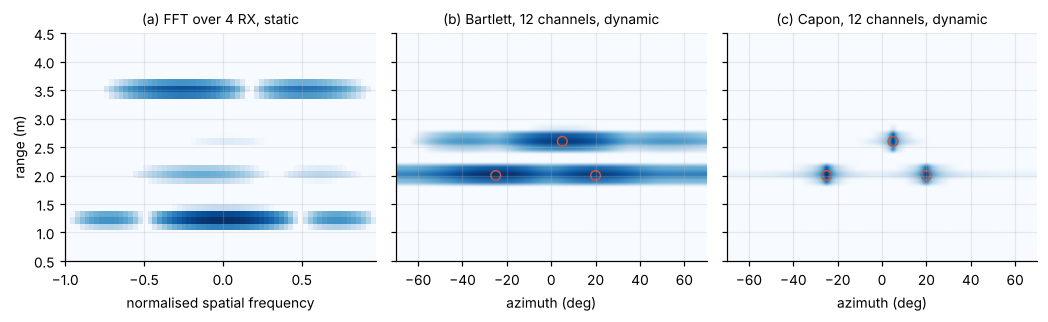

In [2]:
ra_fft = spatial.range_angle_fft(rp[:, :4], n_angle=64)
ra_b = spatial.range_angle_map(rp, pos, angles, "bartlett")
ra_c = spatial.range_angle_map(rp, pos, angles, "capon")

fig, ax = plt.subplots(1, 3, figsize=(9.6, 3.0), sharey=True)
db = lambda m: 10 * np.log10(m / m.max() + 1e-12)
fft_axis = np.linspace(-1, 1, 64, endpoint=False)
ax[0].imshow(db(ra_fft ** 2), aspect="auto", origin="lower", vmin=-30, cmap="Blues",
             extent=[fft_axis[0], fft_axis[-1], rax[0], rax[-1]])
ax[0].set(xlabel="normalised spatial frequency", ylabel="range (m)", title="(a) FFT over 4 RX, static")
for k, (m, lab) in enumerate([(ra_b, "(b) Bartlett, 12 channels, dynamic"), (ra_c, "(c) Capon, 12 channels, dynamic")]):
    ax[k + 1].imshow(db(m), aspect="auto", origin="lower", vmin=-30, cmap="Blues",
                     extent=[angles[0], angles[-1], rax[0], rax[-1]])
    ax[k + 1].set(xlabel="azimuth (deg)", title=lab)
    for p in people:
        ax[k + 1].scatter(p.azimuth_deg, p.range_m, s=40, facecolors="none", edgecolors="#c8553d", lw=1)
ax[0].set_ylim(0.5, 4.5)
plt.tight_layout()

## Picking the people

The number of people is known from the file name (`Man1` to `Man3`), so detection reduces to choosing that many cells. `spatial.pick_targets` walks the cells from the strongest down and accepts a cell only if it is at least `min_sep_m` away from every accepted one, either in range or in cross-range. Cross-range is converted to an angular step at the mean distance of the beds, $\Delta\theta = \arcsin(d_{min}/\bar R)$, which is what turns a rule written in metres into a rule on the map. The first bins are skipped because the transmitter leakage sits there.

When the azimuth axis is too coarse to rank cells reliably, the multi-person version picks ranges first (`spatial.pick_ranges` on the summed map) and resolves angles only inside each chosen bin.

In [3]:
picks = spatial.pick_targets(ra_c, 3, cfg.range_resolution, angles, min_sep_m=0.5, mean_range=2.2)
for r, a in picks:
    print(f"range {rax[r]:.2f} m   azimuth {angles[a]:+.1f} deg")

range 1.99 m   azimuth -25.0 deg
range 2.58 m   azimuth +5.0 deg
range 1.99 m   azimuth +20.0 deg


## Two people in one range bin

At 2.0 m the two people are 45° apart, more than the 28° beamwidth, and yet the Bartlett cut below separates them only by a shallow dip, because each one sits on the skirt of the other's main lobe. Capon separates them. A third option is MUSIC, and it needs one more idea.

MUSIC splits the eigenvectors of $\mathbf R$ into a signal subspace (as many as there are sources) and a noise subspace $\mathbf E_n$, and looks for steering vectors orthogonal to the noise subspace,
$$
P_{M}(\theta) = \frac{1}{\lVert \mathbf E_n^H\,\mathbf a(\theta)\rVert^2}.
$$
This works only if the sources are not coherent. The static echoes of two people are perfectly coherent: they are two constants, and their covariance has rank one whatever their angles. The multi-person version therefore band-pass filters the slow-time signal of every channel to the breathing band before forming $\mathbf R$ (`spatial.music_resp_angles`). The snapshots then contain each person's own breathing, and two people do not breathe in step.

MUSIC peaks (deg): [-25.0, 19.5]


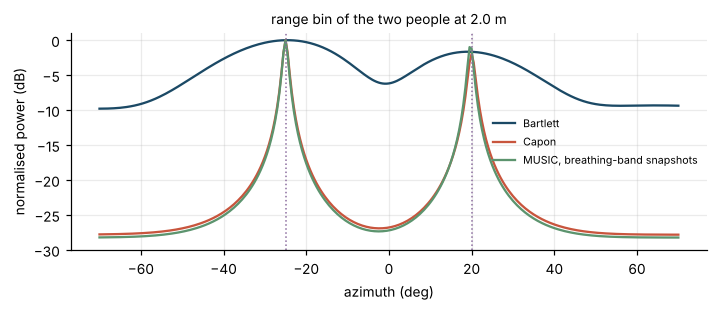

In [4]:
cut_b = ra_b[rb2] / ra_b[rb2].max()
cut_c = ra_c[rb2] / ra_c[rb2].max()
cut_m = spatial.music_resp_angles(rp, rb2, pos, angles, fs, n_sources=2)

fig, ax = plt.subplots(figsize=(6.6, 2.9))
for c, lab in [(cut_b, "Bartlett"), (cut_c, "Capon"), (cut_m, "MUSIC, breathing-band snapshots")]:
    ax.plot(angles, 10 * np.log10(c + 1e-12), label=lab)
for p in people[:2]:
    ax.axvline(p.azimuth_deg, color="#8c6d9f", ls=":", lw=1)
ax.set(ylim=(-30, 1), xlabel="azimuth (deg)", ylabel="normalised power (dB)", title="range bin of the two people at 2.0 m")
ax.legend(fontsize=7, loc="center right")
plt.tight_layout()
print("MUSIC peaks (deg):", [float(angles[i]) for i in spatial.peaks_1d(cut_m, 2, 10)])

## One MVDR beam per person

For each picked cell the beam weights are
$$
\mathbf w = \frac{\mathbf R^{-1}\mathbf a(\theta)}{\mathbf a^H(\theta)\,\mathbf R^{-1}\,\mathbf a(\theta)} ,
$$
with $\mathbf R$ estimated over all frames, chirps and the $\pm$`gate` bins around the target. Three details decide whether the beam is usable:

- **Diagonal loading.** $\mathbf R + \epsilon\,\mathrm{tr}(\mathbf R)/M\,\mathbf I$. Slow-time snapshots are strongly correlated, so the effective number of snapshots is far below the number of frames, and a small error in the steering vector (a chest is not a point) makes plain MVDR null its own target. Loading trades a little interference rejection for that protection.
- **Dynamic covariance, full signal.** The weights come from the covariance after static removal, so they are shaped by the other people rather than by the bed; they are then applied to the full slow-time signal, which keeps the arc of the chest intact for the circle fit.
- **Range gate.** A chest spans more than one bin at 4 cm resolution, and its centre moves with breathing. Summing $\pm1$ bin keeps the echo in the beam.

The phase of each beam, demodulated around its fitted centre, gives the chest displacement of that person.

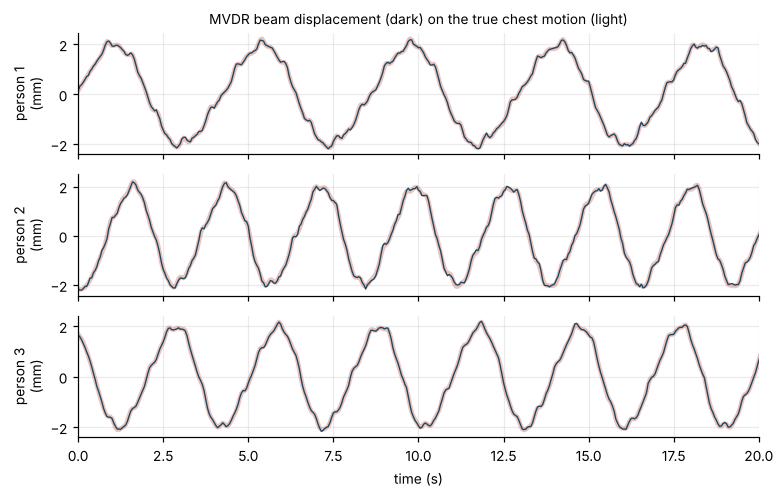

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(7.2, 4.6), sharex=True)
for k, p in enumerate(people):
    z = beams.mvdr_beam(rp, int(round(p.range_m / cfg.range_resolution)), p.azimuth_deg, pos, gate=1)
    d = 1e3 * vitals.displacement(z, cfg.wavelength, vitals.circle_fit(z)[0])
    true = 1e3 * (truth["displacement"][k] - truth["displacement"][k].mean())
    ax[k].plot(t, true, color="#c8553d", lw=3, alpha=0.35)
    ax[k].plot(t, d, lw=0.9, color="#1b4965")
    ax[k].set_ylabel(f"person {k + 1}\n(mm)")
ax[-1].set(xlim=(0, 20), xlabel="time (s)")
ax[0].set_title("MVDR beam displacement (dark) on the true chest motion (light)")
plt.tight_layout()

## Rates and evaluation

In Method A the heart rate comes from the Welch spectrum of the phase rate in 0.8 to 3 Hz. Breathing has two variants: peak intervals on the band-passed amplitude of the beam, and peak intervals on the Hilbert envelope of the breathing-band phase rate, with the Welch peak as fallback when fewer than two peaks are found. The cell below uses `vitals.vital_rates`: phase for breathing, phase rate with harmonic summation for the heart.

Because beams come out in map order, not in bed order, an evaluation has to pair estimates with references. `assign.match` does this with the Hungarian algorithm on the absolute differences of one rate. Matching breathing and heart rate separately can hand a beam the breathing of one person and the heart rate of another, so `assign.match_joint` pairs both rates of a beam with the same person in a single assignment. Either way the pairing uses the references: it says how good the best pairing is, it does not label people by itself. Without a reference, `assign.by_position` labels beams by the nearest bed.

In [6]:
est = []
for r, a in picks:
    z = beams.mvdr_beam(rp, r, angles[a], pos, gate=1)
    est.append(vitals.vital_rates(z, fs, centre=vitals.circle_fit(z)[0]))
est = np.array(est)
print("picked cells -> (RR, HR):", np.round(est, 1).tolist())
ref = [(p.rr, p.hr) for p in people]
for e, r, drr, dhr in assign.match_joint(est, ref):
    print(f"beam {e + 1} -> person {r + 1}   RR difference {drr:+.1f}   HR difference {dhr:+.1f}")

# with a SiViS file the references come from the condition letters in the name
info = sivis.parse_name("146_TopFront_4m_0deg_Man3_CondE_CondG_CondB_ADC256_Chirp128_SR1000_RE60_FR40_Gain30_FS30_IWR_0.bin")
print(info["conditions"], "->", sivis.reference(info["conditions"]))

picked cells -> (RR, HR): [[14.0, 79.8], [19.9, 110.5], [22.0, 89.9]]
beam 1 -> person 1   RR difference +0.0   HR difference -0.2
beam 2 -> person 3   RR difference -0.1   HR difference +0.5
beam 3 -> person 2   RR difference -0.0   HR difference -0.1
['E', 'G', 'B'] -> [(22, 90), (30, 120), (12, 60)]
